# Calculate and Save Indices

In [1]:
### GENERAL SETUP
%matplotlib inline  
# this enables plotting within notebook

#import modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np   # basic math library  you will type np.$STUFF  e.g., np.cos(1)
import numpy.linalg as LA
from matplotlib.gridspec import GridSpec
import timeit
import cartopy.crs as ccrs
import datetime
import scipy.stats as stats # imports stats functions https://docs.scipy.org/doc/scipy/reference/stats.html
import cartopy.feature as cfeature
import cftime

## Functions

In [2]:
def eof(ds_anom):
    # calculate the first and second EOFs/PCs for a given anomaly field using SVD
    ds_anom = ds_anom.where(np.isnan(ds_anom) == False, 0)
    ds_anom_std = ds_anom / ds_anom.std('time')
    ds_anom_std = ds_anom_std.where(np.isnan(ds_anom_std) == False, 0)
    time, lon, lat = ds_anom.time, ds_anom.lon, ds_anom.lat
    
    a,b,c = np.shape(ds_anom.values)  ## have axis sizes for later (a, b, c)
    Y_stand = ds_anom_std.values.reshape(a, b*c);
    Y = ds_anom.values.reshape(a, b*c);
    # print(a,b,c)
    # print(np.shape(Y_stand))
    # print(np.shape(Y))
    
    start_time = timeit.default_timer()
    u,s,v=LA.svd(Y_stand)  ## Barnes Chapter 3 Equation (65)
    elapsed = timeit.default_timer() - start_time
    # print('Time elapsed in LA SVD method: ',elapsed,' seconds')
    
    eof_num = 1
    e1_svd = (v[eof_num-1,:]).reshape(b,c)
    z1_svd = u[:,eof_num-1]*(s[eof_num-1]); z1_svd = (z1_svd-np.mean(z1_svd))/np.std(z1_svd)  
    pc1 = z1_svd
    eof1 = (1./np.size(Y,axis=0))*np.dot(np.transpose(z1_svd),Y)   ## Barnes Chapter 3 Equation (79)
    eof1_plot = eof1.reshape(b,c)  ### this is the reshaped eigenvector to plot
    eof1_plot = xr.DataArray(eof1_plot,dims=['lat','lon'],coords={'lat': lat,'lon': lon})
    pc1 = xr.DataArray(pc1,dims=['time'],coords={'time': time})
    
    eof_num = 2
    e1_svd = (v[eof_num-1,:]).reshape(b,c)
    z1_svd = u[:,eof_num-1]*(s[eof_num-1]); z1_svd = (z1_svd-np.mean(z1_svd))/np.std(z1_svd)  
    pc2 = z1_svd
    eof2 = (1./np.size(Y,axis=0))*np.dot(np.transpose(z1_svd),Y)   ## Barnes Chapter 3 Equation (79)
    eof2_plot = eof2.reshape(b,c)  ### this is the reshaped eigenvector to plot
    eof2_plot = xr.DataArray(eof2_plot,dims=['lat','lon'],coords={'lat': lat,'lon': lon})
    pc2 = xr.DataArray(pc2,dims=['time'],coords={'time': time})    

    eof_full = xr.merge([eof1_plot.to_dataset(name='EOF1'),eof2_plot.to_dataset(name='EOF2')])
    pc_full = xr.merge([pc1.to_dataset(name='PC1'),pc2.to_dataset(name='PC2')])

    return eof_full, pc_full

In [3]:
def detrend(dat, dim, order):
    """ detrend dat along the axis dim with a polynomial of order n"""
    params = dat.polyfit(dim=dim, deg=order)
    fit = xr.polyval(dat[dim], params.polyfit_coefficients)
    dat = dat-fit
    return dat

## Load data

In [4]:
# open the data!
ds = xr.open_dataset('SSH.regrid.nc')['SSH']
ds['time'] = pd.date_range("1958-01", "2020-12", freq="MS")
# center on the Pacific
ds = ds.roll(lon=180,roll_coords=True)
ds['lon'] = np.arange(0.5,360.5,1)
ds = ds/100 # convert to meters for SSH

In [5]:
# calculate the PDO/NPGO using PCA
ssh_fosi = ds
# remove seasonal climatology
ssh_fosi_anom = ssh_fosi.groupby('time.month') - ssh_fosi.groupby('time.month').mean()
ssh_fosi_anom = ssh_fosi_anom.sel(lat=slice(20,62),lon=slice(180,250))

ssh_fosi_anom_detr = detrend(ssh_fosi_anom,'time',1)
## calculate EOFs
%time eof_full, pc_full = eof(ssh_fosi_anom_detr)

strength_npgo = pc_full['PC2']
strength_pdo = pc_full['PC1']

CPU times: user 1.45 s, sys: 36.3 ms, total: 1.49 s
Wall time: 2.28 s


In [28]:
# eof_full['EOF1'].to_netcdf('FOSI.PDO.EOF.nc')
# eof_full['EOF2'].to_netcdf('FOSI.NPGO.EOF.nc')

strength_npgo.to_netcdf('FOSI.NPGO.nc')
strength_pdo.to_netcdf('FOSI.PDO.nc')

In [7]:
# # PCA for SODA data

# # open the data!
# ds = xr.open_dataset('SODA3.15.2_NP_ssh_monmean_1980-2020.regrid.nc').ssh; 
# ds['time'] = pd.date_range('1980-01','2020-12',freq='MS')

# ssh_soda = ds
# # remove seasonal climatology
# ssh_soda_anom = ssh_soda.groupby('time.month') - ssh_soda.groupby('time.month').mean()
# ssh_soda_anom = ssh_soda_anom.sel(lat=slice(20,62),lon=slice(180,250))

# ssh_soda_anom_detr = detrend_linear(ssh_soda_anom,'time',1)
# ## calculate EOFs
# %time explained, eof_full, pc_full = eof(ssh_soda_anom_detr)

# strength_npgo2 = pc_full['PC2']
# strength_pdo2 = pc_full['PC1']

# strength_npgo2.to_netcdf('SODA.NPGO.nc')
# strength_pdo2.to_netcdf('SODA.PDO.nc')

In [8]:
# # CESM2 data

# # CESM2-LE SSH - [need to save separately]
# ssh = xr.open_dataset('/glade/derecho/scratch/smogen/CESM2/SSH.full.regrid.nc')['SSH']
# ssh['time'] = pd.date_range('1950-01','2100-12',freq='MS')
# ssh = ssh.roll(lon=180,roll_coords=True)
# ssh['lon'] = np.arange(0.5,360.5,1)

# # CESM2-LE UVEL - [need to save separately]
# uvel_cesm2 = xr.open_dataset('/glade/derecho/scratch/smogen/CESM2/UVEL.full.regrid.nc')
# uvel_cesm2['time'] = pd.date_range('1950-01','2100-12',freq='MS')
# uvel_cesm2 = uvel_cesm2.roll(lon=180,roll_coords=True)
# uvel_cesm2['lon'] = np.arange(0.5,360.5,1)

## Calculate Indices

In [9]:
data = ssh_fosi # can change which dataset is used

In [10]:
# load alternative datasets of SSH
soda_reg = xr.open_dataset('SODA3.15.2_NP_ssh_monmean_1980-2020.regrid.nc').ssh; soda_reg['time'] = pd.date_range('1980-01','2020-12',freq='MS')

### Latitude of Core

In [11]:
fosi_core = data.sel(lat = slice(35,50),lon=slice(180,200)).differentiate('lat').idxmin('lat').mean('lon')
# fosi_core.to_dataset(name = 'core').to_netcdf('FOSI.Lat.Core.nc')

In [12]:
# cesm2_core = ssh.sel(lat = slice(35,50),lon=slice(180,200)).differentiate('lat').idxmin('lat').mean('lon')
# cesm2_core.to_dataset(name = 'core').to_netcdf('CESM2.Lat.Core.nc')

In [13]:
soda_core = soda_reg.sel(lat = slice(35,50),lon=slice(180,200)).differentiate('lat').idxmin('lat').mean('lon')
# soda_core.to_dataset(name = 'core').to_netcdf('SODA.Lat.Core.nc')

Text(0.5, 1.0, 'LoC comparison')

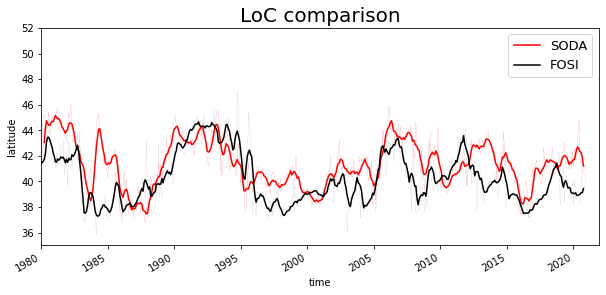

In [14]:
# Figure to compare across datasets
f, ax = plt.subplots(1,1,figsize=(10,4))
soda_reg.sel(lat = slice(35,50),lon=slice(180,200)).differentiate('lat').idxmin('lat').mean('lon').plot(color='red',alpha=0.5,linewidth=.2)
soda_reg.sel(lat = slice(35,50),lon=slice(180,200)).differentiate('lat').idxmin('lat').mean('lon').rolling(time=6,center=True).mean().plot(color='red',label='SODA',alpha=1,linewidth=1.5)

fosi_core.plot(color='k',linewidth=0.1,alpha=0.5)
fosi_core.rolling(time=6,center=True).mean().plot(color='k',label='FOSI')

plt.ylabel('latitude')
plt.legend(fontsize=13)
plt.ylim(35,52)
plt.xlim('1980-01','2021-12')
plt.title('LoC comparison',fontsize=20)

### Latitude of Bifurcation

In [15]:
# rewrite function sans loop then apply below
def lat_of_contour_bifurcation(ds, lat, lon, lon_of_interest):

    ds = xr.DataArray(
        ds,
        dims=['lat', 'lon'],
        coords={
            'lat': lat,
            'lon': lon
        }
    )
    
    cs = ds.plot.contour(levels=np.arange(-0.3,0.35,0.05))
    plt.close()

    # select the SSH values at a given longitude (usually 230.5)
    test_ssh = ds.sel(lon = lon_of_interest)
    
    # extract the values for each contour
    contours = {}
    for level, segments in zip(cs.levels, cs.allsegs):
        contours[level] = []
        for segment in segments:
            lon = segment[:, 0]
            lat = segment[:, 1]
            contours[level].append(segment)
    
    # removes where the given contour value does not create a line (in this domain); i.e. if the contour is empty
    filtered_data = {key: value for key, value in contours.items() if value}
    
    # for each 
    levels_to_use = []
    difference_save=[]
    difference_save_cen = []
    contour_of_interest_save = []
    for i in range(len(filtered_data)):
        # coordinates for values across the domain (east-west)
        # filter for the longest length line for each contour value (the one that moves across the domain where we are interested)
        rig = max(filtered_data[list(filtered_data.keys())[i]], key=len)[0] # coordinates for the right most value of each contour
        # left= max(filtered_data[list(filtered_data.keys())[i]], key=len)[-1]# coordinates for the 2nd left most value
        cen = max(filtered_data[list(filtered_data.keys())[i]], key=len)[int(np.round(len(max(filtered_data[list(filtered_data.keys())[i]], key=len))/2))]# coordinates for the 2nd left most value
    
        # does the latitude move N-S when moving from central to the right
        diff2 = rig[1] - cen[1] # does the latitude move north (+) or south (-)??

        # append values of the SSH contour at each location
        levels_to_use.append(list(filtered_data.keys())[i])
        # append the diff
        difference_save_cen.append(diff2)
        # save latitude of the central value
        
    # isolate the contour value when the difference is positive to negative 
    contour_of_interest_cen = levels_to_use[np.sign(difference_save_cen).argmin()]# - 0.025

    # find the latitude where SSH is closest to the contour of interest at [insert longitude]
    latitude_final_down_cen = (abs(test_ssh - (contour_of_interest_cen - 0.025))).idxmin()

    avg_cen = (latitude_final_down_cen)
    avg_cen['lon_calc'] = float(lon_of_interest)
    del cs, contours, levels_to_use, difference_save_cen, test_ssh
    return avg_cen

In [16]:
def LoB_across_lon(ds, lon_range):
    ssh_smooth = ds
    lat = ssh_smooth.lat
    lon = ssh_smooth.lon
    # apply over a range of longitudes
    lon_range = lon_range

    res = []
    for value in lon_range:
        # print(value)
        result = xr.apply_ufunc(
            lat_of_contour_bifurcation,
            ssh_smooth, lat.values, lon.values, value,
            input_core_dims=[
                ['lat', 'lon'],  # ssh: 2D array
                ['lat'],         # lat: 1D array
                ['lon'],         # lon: 1D array
                []               # float value (0d)
            ],
            output_core_dims=[[]],
            vectorize=True,
        )
        res.append(result)
    
    final_results = xr.concat(res,'lon_calc')
    final_results['lon_calc'] = lon_range
    del res
    return final_results

In [17]:
%%time
print('FOSI')
fosi_smooth = LoB_across_lon(data.rolling(lon=3,lat=3,center=True).mean().sel(lat = slice(30,50),lon=slice(225,240)), lon_range = np.arange(225.5,230.5,1))
# fosi_smooth.to_dataset(name='bifurcation').to_netcdf('FOSI.Lat.Bifu.contour.nc')

FOSI
CPU times: user 1min 27s, sys: 2.07 s, total: 1min 29s
Wall time: 1min 34s


In [18]:
%%time 
print('SODA')
soda_smooth = LoB_across_lon(soda_reg.rolling(lon=3,lat=3,center=True).mean().sel(lat = slice(30,50),lon=slice(225,240)), lon_range = np.arange(225.5,230.5,1))
# soda_smooth.to_dataset(name='bifurcation').to_netcdf('SODA.Lat.Bifu.contour.nc')

SODA
CPU times: user 59.3 s, sys: 1.07 s, total: 1min
Wall time: 1min 4s


In [19]:
# %%time
# ssh_cesm2_smooth = ssh.sel(lat = slice(29,56),lon=slice(209,241)).rolling(lon=3,lat=3,center=True).mean().sel(lat = slice(30,55),lon=slice(210,240))
# lat = ssh_cesXm2_smooth.lat
# lon = ssh_cesm2_smooth.lon

In [20]:
# # %%time
# #
# for i in range(0,20):
#     print(i)
#     # tmp = LoB_across_lon(ssh_cesm2_smooth.isel(member=i), lon_range = np.arange(225.5,230.5,1))
#     %time tmp = LoB_across_lon(ssh_cesm2_smooth.isel(member=i), lon_range = np.arange(225.5,230.5,1))
#     print('   success!')
#     %time tmp.to_dataset(name='bifurcation').to_netcdf('./CESM2.LoB/CESM2.Lat.Bifu.member' + str(i) + '.contour.wider_range.nc')
#     del tmp

Text(0.5, 1.0, 'LoB comparison')

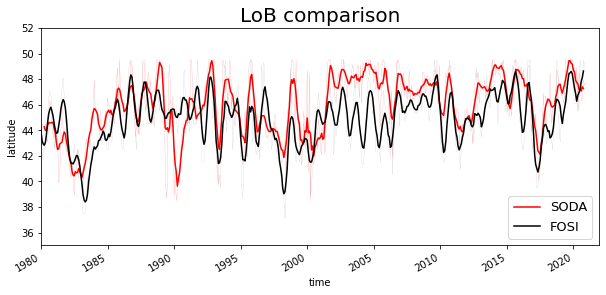

In [21]:
# Figure to compare across datasets
f, ax = plt.subplots(1,1,figsize=(10,4))
soda_smooth.mean('lon_calc').plot(color='red',alpha=0.5,linewidth=.2)
soda_smooth.mean('lon_calc').rolling(time=6,center=True).mean().plot(color='red',label='SODA',alpha=1,linewidth=1.5)

fosi_smooth.mean('lon_calc').plot(color='k',linewidth=0.1,alpha=0.5)
fosi_smooth.mean('lon_calc').rolling(time=6,center=True).mean().plot(color='k',label='FOSI')

plt.ylabel('latitude')
plt.legend(fontsize=13)
plt.ylim(35,52)
plt.xlim('1980-01','2021-12')
plt.title('LoB comparison',fontsize=20)

### Strength of Core

In [29]:
uvel = xr.open_dataset('UVEL.regrid.nc')['UVEL'].isel(z_t = 0)#.sel(z_t=slice(0,10000))
uvel = uvel.roll(lon=180,roll_coords=True)
uvel['lon'] = np.arange(0.5,360.5,1)
uvel['time'] = pd.date_range("1958-01", "2020-12", freq="MS")

# select region around the LoC
lat_min = np.round(fosi_core,0) - 1
lat_max = np.round(fosi_core,0) + 1

uvel_west = uvel.sel(lon = slice(180,200)).mean('lon')
strength = uvel.where(uvel_west.lat < lat_max).where(uvel_west.lat > lat_min).mean('lat')
strength = strength.sel(lon = slice(180,200)).mean('lon')
# strength.to_dataset(name='strength').to_netcdf('FOSI.UVEL.strength.nc')

In [24]:
# # CESM2
# # select region around the LoC
# lat_min = np.round(cesm2_core,0) - 1
# lat_max = np.round(cesm2_core,0) + 1

# uvel_west = uvel.sel(lon = slice(180,200)).mean('lon')
# strength_cesm2 = uvel_cesm2.where(uvel_west.lat < lat_max).where(uvel_west.lat > lat_min).mean('lat')

# strength_cesm2.to_dataset(name='strength').to_netcdf('CESM2.UVEL.strength.nc')

In [32]:
# Mer (from SODA 8/18/25)
mer = pd.read_csv('/glade/work/smogen/CVP_bifurcation/data/soda_npc_core_strength_indexes.csv')

year = mer['year']
month = mer['month']

df = pd.DataFrame({'year': year.values,
                   'month': month.values,
                   'day': (np.zeros_like(month.values) + 1)})

time = pd.to_datetime(df)

mer_lat = mer['core']
mer_speed = mer['speed']
mer_speeda = mer['speeda']
mer_ugeo = mer['ugeo']
mer_ugeoa = mer['ugeoa']

mer_index = xr.DataArray(mer_lat)
mer_index = mer_index.to_dataset()
mer_index = mer_index.assign(speed = mer_speed, speeda = mer_speeda, ugeo = mer_ugeo, ugeoa = mer_ugeoa)

mer_index = mer_index.rename({'dim_0':'time'})
mer_index['time'] = time.values

# mer_index.to_netcdf('SODA.Core.strength.nc')

(3652.0, 18962.0)

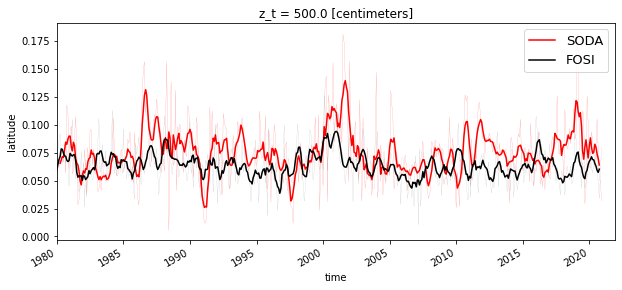

In [31]:
# Figure to compare across datasets
f, ax = plt.subplots(1,1,figsize=(10,4))
mer_index.ugeo.plot(color='red',alpha=0.5,linewidth=.2)
mer_index.ugeo.rolling(time=6,center=True).mean().plot(color='red',label='SODA',alpha=1,linewidth=1.5)

(strength/100).plot(color='k',linewidth=0.1,alpha=0.5)
(strength/100).rolling(time=6,center=True).mean().plot(color='k',label='FOSI')

plt.ylabel('latitude')
plt.legend(fontsize=13)
# plt.ylim(35,52)
plt.xlim('1980-01','2021-12')
# plt.title('SoC comparison',fontsize=20)